# Лабораторна робота 4. Методи класифікації. Дерева рішень
**Мова:** Python · **Бібліотека:** scikit-learn · **Середовище:** Google Colab

Завдання: побудувати дерево регресії CART для даних `algae` (прогноз водоростей a1), дослідити залежність помилки від глибини дерева, виконати відсікання за вузлами та за рівнями, побудувати дерево класифікації для `iris.dat` і оцінити його точність. Додатково — класифікація набору `heart`.

Перед запуском завантажте у панель «Файли» (ліворуч) файли `iris.dat` і `heart.csv`. Набір `algae` завантажується автоматично з репозиторію пакета DMwR2.

## 1. Підключення бібліотек

In [ ]:
!pip -q install pyreadr

import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadr
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, RepeatedKFold, StratifiedKFold, GridSearchCV)
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import sklearn
print('scikit-learn', sklearn.__version__)
SEED = 42

scikit-learn 1.9.1


## 2. Дані algae
Дані про 200 проб води: сезон, розмір і швидкість річки, 8 гідрохімічних показників та частота 7 груп водоростей (a1–a7). Як і в методичці, прогнозуємо **a1** за першими 11 ознаками.

In [ ]:
# Завантажуємо оригінальний набір algae з пакета DMwR2 (той самий, що в R: data(algae, package='DMwR2'))
url = 'https://raw.githubusercontent.com/cran/DMwR2/master/data/algae.RData'
urllib.request.urlretrieve(url, 'algae.RData')
algae = pyreadr.read_r('algae.RData')['algae']
print('Розмір:', algae.shape)
algae.head()

Розмір: (200, 18)


,season,size,speed,mxPH,mnO2,Cl,NO3,NH4,oPO4,PO4,Chla,a1,a2,a3,a4,a5,a6,a7
0,winter,small,medium,8.00,9.8,60.800,6.238,578.00000,105.000,170.00000,50.0,0.0,0.0,0.0,0.0,34.2,8.3,0.0
1,spring,small,medium,8.35,8.0,57.750,1.288,370.00000,428.750,558.75000,1.3,1.4,7.6,4.8,1.9,6.7,0.0,2.1
2,autumn,small,medium,8.10,11.4,40.020,5.330,346.66699,125.667,187.05701,15.6,3.3,53.6,1.9,0.0,0.0,0.0,9.7
3,spring,small,medium,8.07,4.8,77.364,2.302,98.18200,61.182,138.70000,1.4,3.1,41.0,18.9,0.0,1.4,0.0,1.4
4,autumn,small,medium,8.06,9.0,55.350,10.416,233.70000,58.222,97.58000,10.5,9.2,2.9,7.5,0.0,7.5,4.1,1.0


In [ ]:
# Аналог manyNAs(): видаляємо проби, де пропущено понад 20% значень (у R це рядки 62 і 199)
na_share = algae.iloc[:, :11].isna().mean(axis=1)
print('Видаляємо рядки (нумерація як у R):', list(algae.index[na_share > 0.2] + 1))
algae = algae[na_share <= 0.2].reset_index(drop=True)

# Ознаки: перші 11 стовпців; сезон, розмір і швидкість кодуємо 0/1 (one-hot)
X = pd.get_dummies(algae.iloc[:, :11], columns=['season', 'size', 'speed'], dtype=int)
y = algae['a1']
print('Проб:', len(X), '| ознак після кодування:', X.shape[1])
print('Пропусків, що залишились:', int(X.isna().sum().sum()), '(дерево scikit-learn >= 1.3 обробляє NaN саме)')

Видаляємо рядки (нумерація як у R): [62, 199]
Проб: 198 | ознак після кодування: 18
Пропусків, що залишились: 21 (дерево scikit-learn >= 1.3 обробляє NaN саме)


## 3. Повне дерево регресії (аналог `rpart`)
Параметри `min_samples_split=20`, `min_samples_leaf=7` відповідають стандартним `minsplit` і `minbucket` у `rpart`. Критерій розбиття — мінімум суми квадратів відхилень (як у CART).

In [ ]:
rt_a1 = DecisionTreeRegressor(min_samples_split=20, min_samples_leaf=7, random_state=SEED)
rt_a1.fit(X, y)
print('Листків:', rt_a1.get_n_leaves(), '| глибина:', rt_a1.get_depth())
print(export_text(rt_a1, feature_names=list(X.columns), decimals=2))

Листків: 16 | глибина: 9
|--- Cl <= 7.29
|   |--- mnO2 <= 10.85
|   |   |--- season_winter <= 0.50
|   |   |   |--- value: [35.71]
|   |   |--- season_winter >  0.50
|   |   |   |--- value: [48.23]
|   |--- mnO2 >  10.85
|   |   |--- value: [55.14]
|--- Cl >  7.29
|   |--- PO4 <= 43.82
|   |   |--- value: [30.58]
|   |--- PO4 >  43.82
|   |   |--- oPO4 <= 51.12
|   |   |   |--- mnO2 <= 10.05
|   |   |   |   |--- oPO4 <= 24.92
|   |   |   |   |   |--- value: [6.75]
|   |   |   |   |--- oPO4 >  24.92
|   |   |   |   |   |--- mnO2 <= 9.40
|   |   |   |   |   |   |--- value: [14.76]
|   |   |   |   |   |--- mnO2 >  9.40
|   |   |   |   |   |   |--- value: [30.74]
|   |   |   |--- mnO2 >  10.05
|   |   |   |   |--- speed_high <= 0.50
|   |   |   |   |   |--- value: [3.65]
|   |   |   |   |--- speed_high >  0.50
|   |   |   |   |   |--- value: [10.99]
|   |   |--- oPO4 >  51.12
|   |   |   |--- NH4 <= 1106.66
|   |   |   |   |--- PO4 <= 104.95
|   |   |   |   |   |--- value: [9.36]
|   |   |

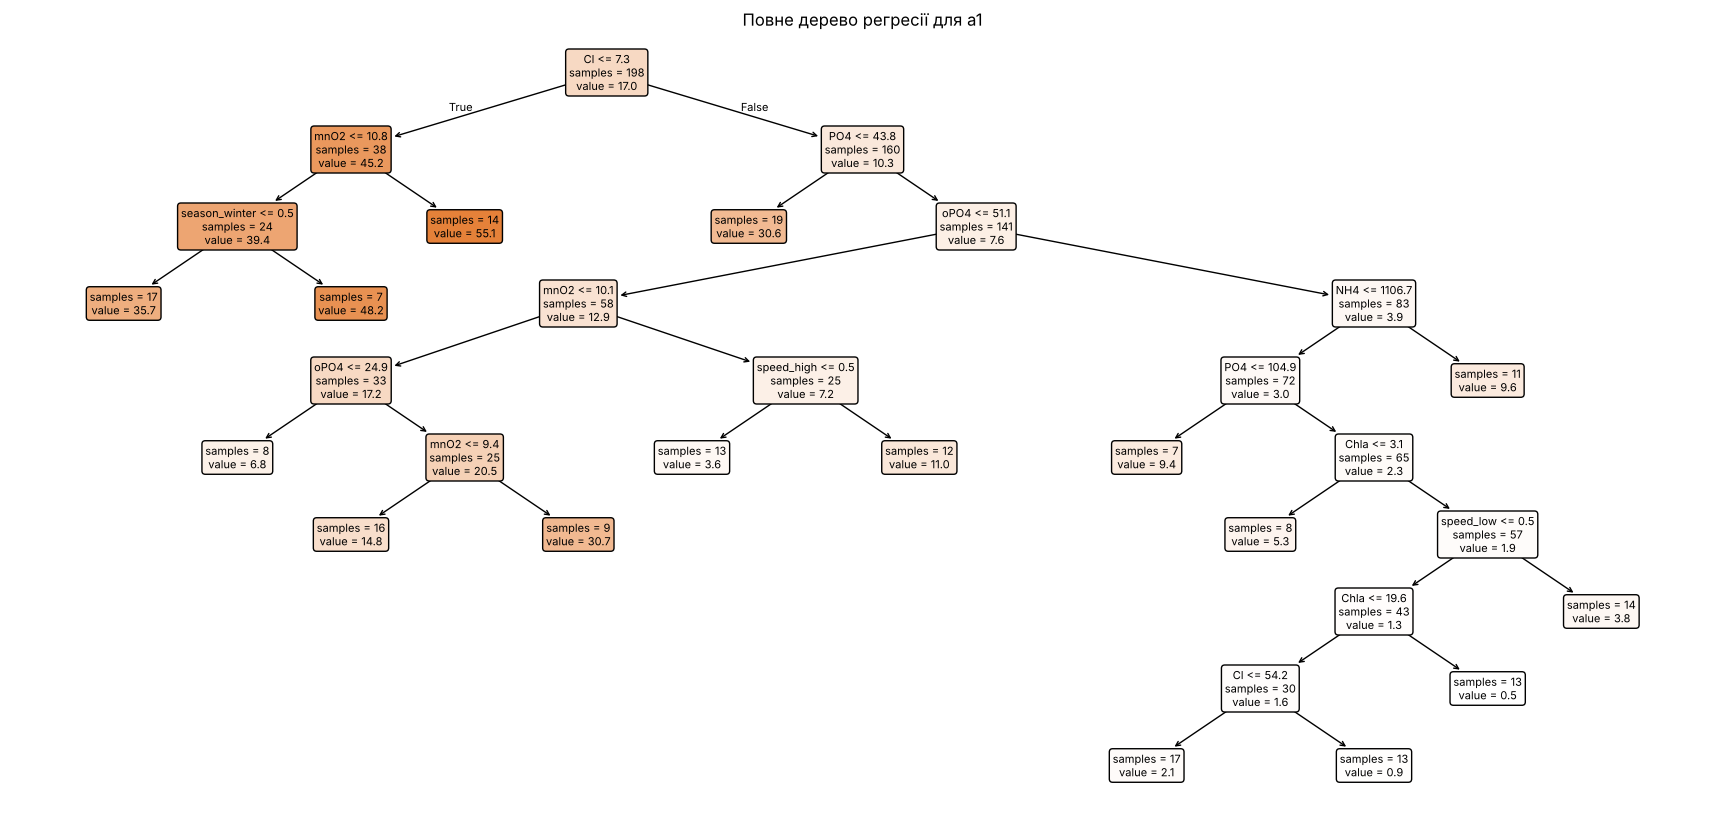

In [ ]:
# Графічне подання дерева (аналог prp / prettyTree)
plt.figure(figsize=(22, 10))
plot_tree(rt_a1, feature_names=X.columns, filled=True, rounded=True, impurity=False, precision=1, fontsize=8)
plt.title('Повне дерево регресії для a1')
plt.show()

## 4. Залежність помилки від кількості рівнів дерева
Для глибини 1–12 рахуємо помилку навчання і помилку 10-кратної перехресної перевірки з 3 повторами (RMSE).

,depth,leaves,train_rmse,cv_rmse,cv_se
0,1,2,16.243,17.797,0.718
1,2,4,14.569,17.544,0.764
2,3,6,13.698,17.001,0.741
3,4,8,13.274,17.647,0.764
4,5,11,12.972,17.843,0.752
5,6,13,12.835,17.889,0.744
6,7,14,12.810,17.877,0.745
7,8,15,12.805,17.875,0.745
8,9,16,12.804,17.877,0.744
9,10,16,12.804,17.877,0.744


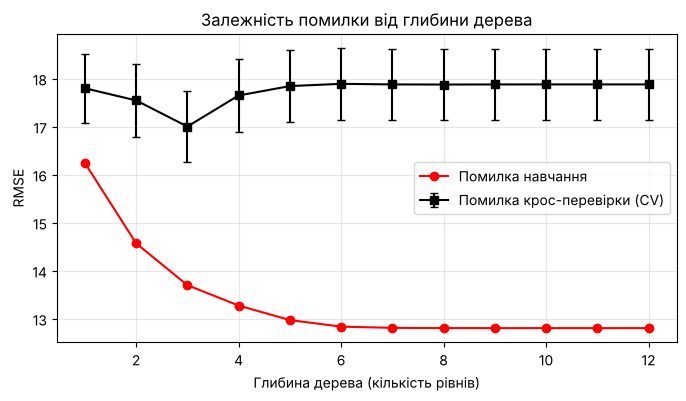

In [ ]:
# 10-кратна перехресна перевірка з 3 повторами — оцінка стабільніша, ніж один прохід
cv = RepeatedKFold(n_splits=10, n_repeats=3, random_state=SEED)
rows = []
for depth in range(1, 13):
    m = DecisionTreeRegressor(max_depth=depth, min_samples_split=20, min_samples_leaf=7, random_state=SEED)
    res = cross_validate(m, X, y, cv=cv, scoring='neg_root_mean_squared_error', return_train_score=True)
    m.fit(X, y)
    rows.append(dict(depth=depth, leaves=m.get_n_leaves(),
                     train_rmse=-res['train_score'].mean(), cv_rmse=-res['test_score'].mean(),
                     cv_se=res['test_score'].std() / np.sqrt(30)))
by_depth = pd.DataFrame(rows)
display(by_depth.round(3))

plt.figure(figsize=(8, 4))
plt.plot(by_depth.depth, by_depth.train_rmse, 'o-', color='red', label='Помилка навчання')
plt.errorbar(by_depth.depth, by_depth.cv_rmse, yerr=by_depth.cv_se, fmt='s-', color='black', capsize=3, label='Помилка крос-перевірки (CV)')
plt.xlabel('Глибина дерева (кількість рівнів)'); plt.ylabel('RMSE')
plt.title('Залежність помилки від глибини дерева'); plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 5. Відсікання за вузлами: штраф на складність (аналог `cp`, `plotcp`, `prune`)
У scikit-learn штраф на складність задається параметром `ccp_alpha` (cost complexity pruning). `cost_complexity_pruning_path` повертає всі значення α, за яких від дерева відсікається чергова гілка. Для кожного α оцінюємо дерево перехресною перевіркою (як `plotcp`) і обираємо α з мінімальною помилкою CV — так само, як у методичці обрано cp = 0.029.

Мінімум CV RMSE = 17.032 при alpha = 13.95 (3 листків)
Правило 1-SE (найпростіше дерево в межах min+SE): alpha = 44.78, листків: 2


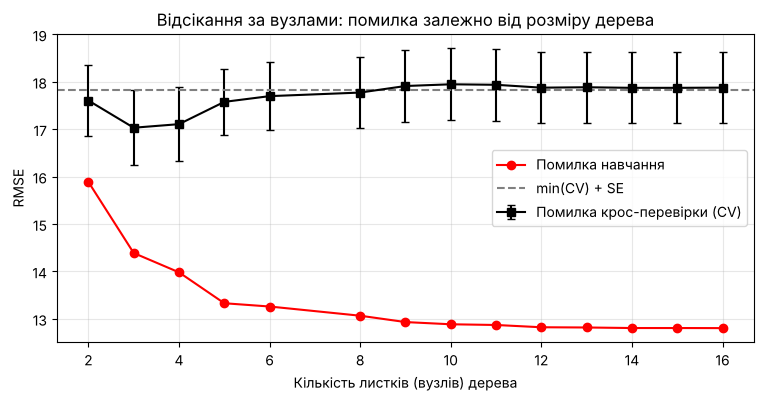

In [ ]:
full = DecisionTreeRegressor(min_samples_split=20, min_samples_leaf=7, random_state=SEED).fit(X, y)
path = full.cost_complexity_pruning_path(X, y)
alphas = np.unique(path.ccp_alphas)[:-1]          # останнє α дає дерево з одного кореня

rows = []
for a in alphas:
    m = DecisionTreeRegressor(ccp_alpha=a, min_samples_split=20, min_samples_leaf=7, random_state=SEED)
    res = cross_validate(m, X, y, cv=cv, scoring='neg_root_mean_squared_error', return_train_score=True)
    m.fit(X, y)
    rows.append(dict(alpha=a, leaves=m.get_n_leaves(), train_rmse=-res['train_score'].mean(),
                     cv_rmse=-res['test_score'].mean(), cv_se=res['test_score'].std() / np.sqrt(30)))
by_alpha = pd.DataFrame(rows)

best = by_alpha.cv_rmse.idxmin()
limit = by_alpha.cv_rmse[best] + by_alpha.cv_se[best]               # правило 1-SE
alpha_1se = by_alpha[by_alpha.cv_rmse <= limit].alpha.max()       # найпростіше дерево в межах 1 SE
print(f'Мінімум CV RMSE = {by_alpha.cv_rmse[best]:.3f} при alpha = {by_alpha.alpha[best]:.2f} ({by_alpha.leaves[best]} листків)')
alpha_best = by_alpha.alpha[best]
print(f'Правило 1-SE (найпростіше дерево в межах min+SE): alpha = {alpha_1se:.2f}, листків: {by_alpha.leaves[by_alpha.alpha == alpha_1se].iloc[0]}')

plt.figure(figsize=(9, 4))
plt.plot(by_alpha.leaves, by_alpha.train_rmse, 'o-', color='red', label='Помилка навчання')
plt.errorbar(by_alpha.leaves, by_alpha.cv_rmse, yerr=by_alpha.cv_se, fmt='s-', color='black', capsize=3, label='Помилка крос-перевірки (CV)')
plt.axhline(limit, ls='--', color='gray', label='min(CV) + SE')
plt.xlabel('Кількість листків (вузлів) дерева'); plt.ylabel('RMSE')
plt.title('Відсікання за вузлами: помилка залежно від розміру дерева'); plt.legend(); plt.grid(True, alpha=.3); plt.show()

Листків після відсікання: 3 | глибина: 2
|--- Cl <= 7.29
|   |--- value: [45.17]
|--- Cl >  7.29
|   |--- PO4 <= 43.82
|   |   |--- value: [30.58]
|   |--- PO4 >  43.82
|   |   |--- value: [7.57]



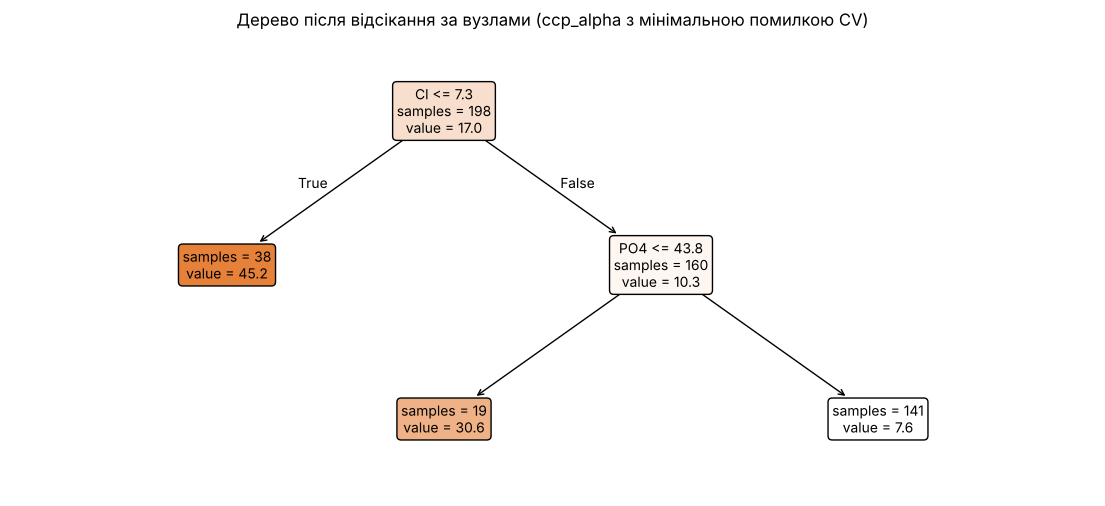

In [ ]:
# Відсічене дерево (аналог prune(rtp.a1, cp = ...))
rtp_a1 = DecisionTreeRegressor(ccp_alpha=alpha_best, min_samples_split=20, min_samples_leaf=7, random_state=SEED).fit(X, y)
print('Листків після відсікання:', rtp_a1.get_n_leaves(), '| глибина:', rtp_a1.get_depth())
print(export_text(rtp_a1, feature_names=list(X.columns), decimals=2))
plt.figure(figsize=(14, 6))
plot_tree(rtp_a1, feature_names=X.columns, filled=True, rounded=True, impurity=False, precision=1, fontsize=10)
plt.title('Дерево після відсікання за вузлами (ccp_alpha з мінімальною помилкою CV)'); plt.show()

## 6. Оптимізація параметра складності з повторною перехресною перевіркою (аналог `caret::train`)
30 значень `ccp_alpha`, 10-кратна перехресна перевірка з 3 повторами.

Найкраще ccp_alpha = 20.08, RMSE = 16.720


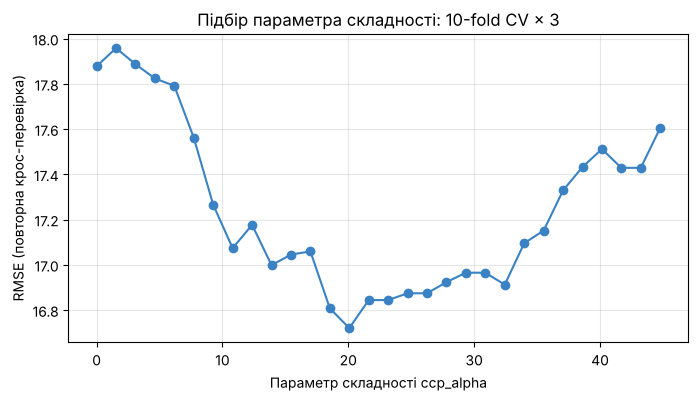

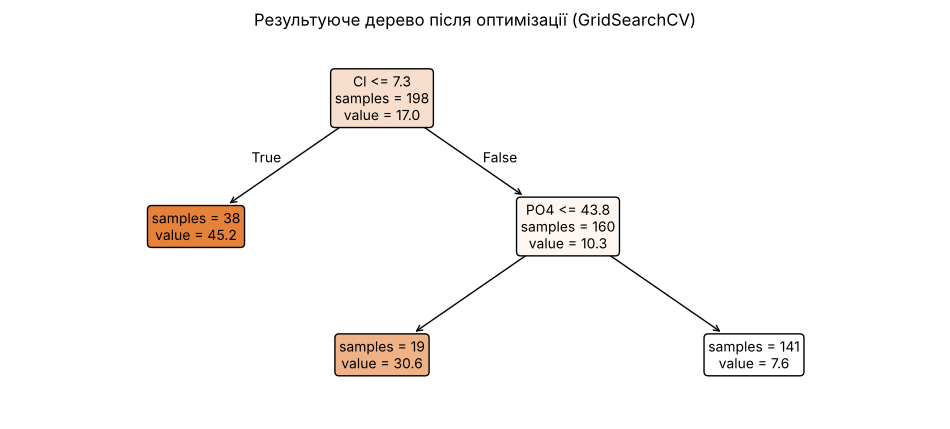

In [ ]:
grid = np.linspace(0, alphas.max(), 30)
cv_rep = RepeatedKFold(n_splits=10, n_repeats=3, random_state=SEED)
search = GridSearchCV(DecisionTreeRegressor(min_samples_split=20, min_samples_leaf=7, random_state=SEED),
                      {'ccp_alpha': grid}, cv=cv_rep, scoring='neg_root_mean_squared_error')
search.fit(X, y)
rmse = -search.cv_results_['mean_test_score']
print(f"Найкраще ccp_alpha = {search.best_params_['ccp_alpha']:.2f}, RMSE = {-search.best_score_:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(grid, rmse, 'o-', color='#3b82c4')
plt.xlabel('Параметр складності ccp_alpha'); plt.ylabel('RMSE (повторна крос-перевірка)')
plt.title('Підбір параметра складності: 10-fold CV × 3'); plt.grid(True, alpha=.3); plt.show()

rtt_a1 = search.best_estimator_
plt.figure(figsize=(12, 5))
plot_tree(rtt_a1, feature_names=X.columns, filled=True, rounded=True, impurity=False, precision=1, fontsize=10)
plt.title('Результуюче дерево після оптимізації (GridSearchCV)'); plt.show()

## 7. Порівняння відсікання за рівнями та за вузлами

In [ ]:
best_depth = int(by_depth.loc[by_depth.cv_rmse.idxmin(), 'depth'])
models = {
    'Повне дерево': rt_a1,
    f'Відсікання за рівнями (max_depth={best_depth})': DecisionTreeRegressor(max_depth=best_depth, min_samples_split=20, min_samples_leaf=7, random_state=SEED),
    'Відсікання за вузлами (ccp_alpha, мін. CV)': rtp_a1,
    'Відсікання за правилом 1-SE': DecisionTreeRegressor(ccp_alpha=alpha_1se, min_samples_split=20, min_samples_leaf=7, random_state=SEED),
    'Оптимізоване GridSearchCV': rtt_a1,
}
rows = []
for name, m in models.items():
    s = -cross_val_score(m, X, y, cv=cv_rep, scoring='neg_root_mean_squared_error')
    m.fit(X, y)
    rows.append(dict(Модель=name, Листків=m.get_n_leaves(), Глибина=m.get_depth(), **{'CV RMSE': s.mean().round(3), 'SE': (s.std()/np.sqrt(len(s))).round(3)}))
comparison_a1 = pd.DataFrame(rows)
comparison_a1

,Модель,Листків,Глибина,CV RMSE,SE
0,Повне дерево,16,9,17.877,0.744
1,Відсікання за рівнями (max_depth=3),6,3,17.001,0.741
2,"Відсікання за вузлами (ccp_alpha, мін. CV)",3,2,17.032,0.796
3,Відсікання за правилом 1-SE,2,1,17.605,0.757
4,Оптимізоване GridSearchCV,3,2,16.720,0.845


## 8. Класифікація ірисів (iris.dat)
Файл містить 150 рядків по 4 ознаки (довжина і ширина чашолистка та пелюстки). Перші 50 — *setosa*, наступні 50 — *versicolor*, останні 50 — *virginica*.

In [ ]:
if not os.path.exists('iris.dat'):
    from google.colab import files
    files.upload()                      # оберіть файл iris.dat

vals = np.array(open('iris.dat').read().split(), dtype=float)
n, k = int(vals[0]), int(vals[1])       # перший рядок файлу: 150 4
Xi = pd.DataFrame(vals[2:].reshape(n, k), columns=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'])
classes = np.array(['setosa', 'versicolor', 'virginica'])
yi = pd.Series(np.repeat(classes, 50), name='species')
print(Xi.shape); Xi.head()

(150, 4)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
# Навчальна (70%) і тестова (30%) вибірки зі збереженням пропорцій класів
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=SEED)
iris_tree = DecisionTreeClassifier(criterion='gini', min_samples_leaf=2, random_state=SEED).fit(Xtr, ytr)
pred = iris_tree.predict(Xte)
print(f'Точність на тестовій вибірці: {accuracy_score(yte, pred)*100:.2f}%  ({(pred == yte).sum()} з {len(yte)})')
cvs = cross_val_score(DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED), Xi, yi,
                      cv=StratifiedKFold(10, shuffle=True, random_state=SEED))
print(f'Точність 10-кратної перехресної перевірки: {cvs.mean()*100:.2f}% ± {cvs.std()*100:.2f}%')
print(classification_report(yte, pred, digits=3))
print(export_text(iris_tree, feature_names=list(Xi.columns)))

Точність на тестовій вибірці: 88.89%  (40 з 45)
Точність 10-кратної перехресної перевірки: 94.00% ± 4.67%
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.778     0.933     0.848        15
   virginica      0.917     0.733     0.815        15

    accuracy                          0.889        45
   macro avg      0.898     0.889     0.888        45
weighted avg      0.898     0.889     0.888        45

|--- petal_length <= 2.45
|   |--- class: setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.55
|   |   |--- petal_length <= 4.85
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.85
|   |   |   |--- class: versicolor
|   |--- petal_width >  1.55
|   |   |--- petal_width <= 1.70
|   |   |   |--- class: versicolor
|   |   |--- petal_width >  1.70
|   |   |   |--- petal_length <= 4.85
|   |   |   |   |--- class: versicolor
|   |   |   |--- petal_length >  4.85
|   |   |   |   |--- class

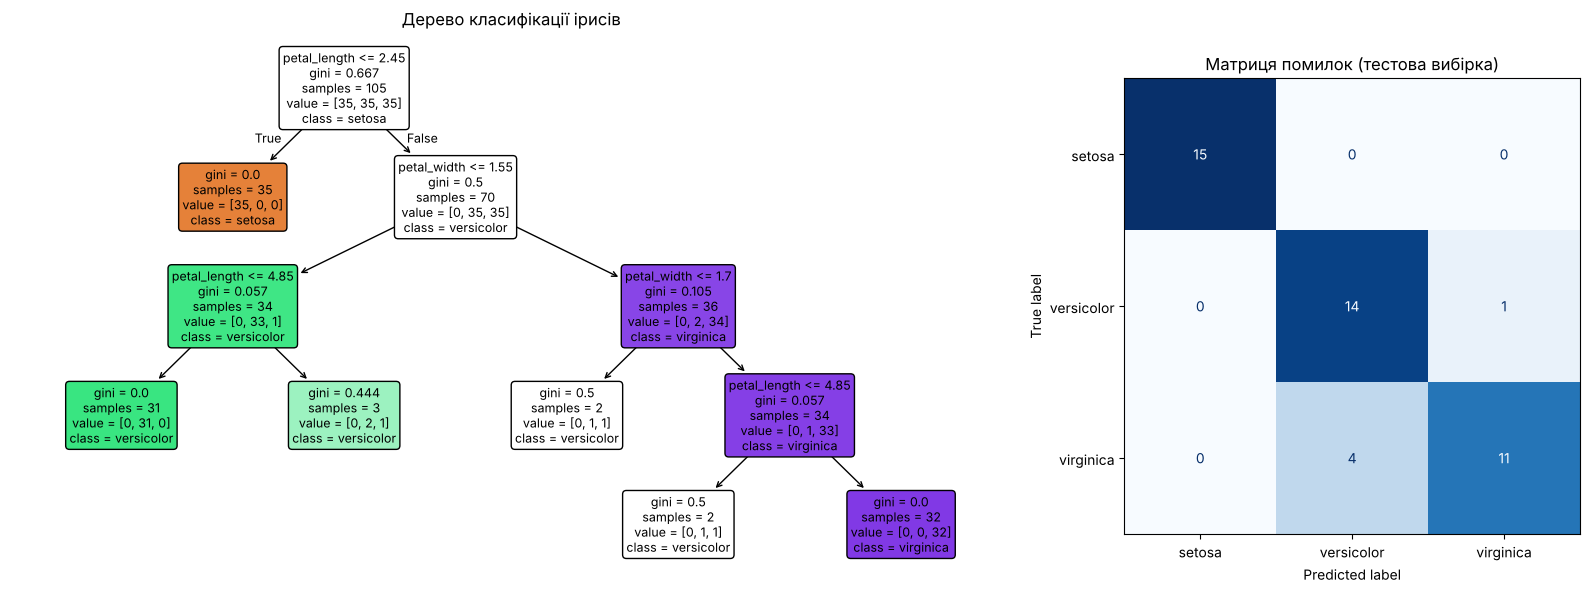

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [2.2, 1]})
plot_tree(iris_tree, feature_names=Xi.columns, class_names=classes, filled=True, rounded=True, fontsize=9, ax=ax[0])
ax[0].set_title('Дерево класифікації ірисів')
ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=classes), display_labels=classes).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Матриця помилок (тестова вибірка)')
plt.tight_layout(); plt.show()

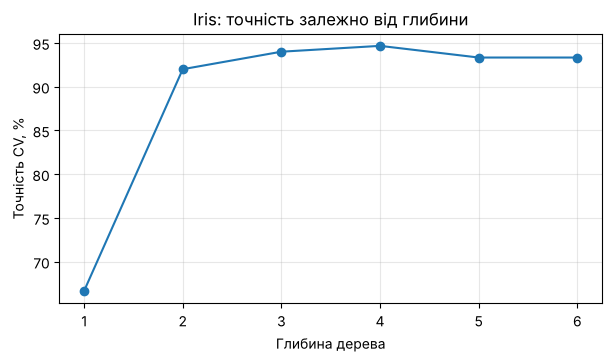

{1: 66.67, 2: 92.0, 3: 94.0, 4: 94.67, 5: 93.33, 6: 93.33}


In [ ]:
# Залежність точності від глибини дерева для ірисів
acc = []
for d in range(1, 7):
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    acc.append(cross_val_score(m, Xi, yi, cv=StratifiedKFold(10, shuffle=True, random_state=SEED)).mean())
plt.figure(figsize=(7, 3.5)); plt.plot(range(1, 7), np.array(acc)*100, 'o-')
plt.xlabel('Глибина дерева'); plt.ylabel('Точність CV, %'); plt.title('Iris: точність залежно від глибини'); plt.grid(True, alpha=.3); plt.show()
print({d: round(float(a)*100, 2) for d, a in zip(range(1, 7), acc)})

## 9. Додатково: класифікація набору heart
303 пацієнти, 5 бінарних ознак (стать, тип болю в грудях, цукор натще, ЕКГ у спокої, стенокардія при навантаженні); `target` — наявність захворювання серця.

(303, 6) | частка target=1: 0.545


Точність CV за глибиною: {1: 75.88, 2: 75.88, 3: 77.23, 4: 77.24, 5: 76.25}
Глибина 3: точність на тесті 70.33%


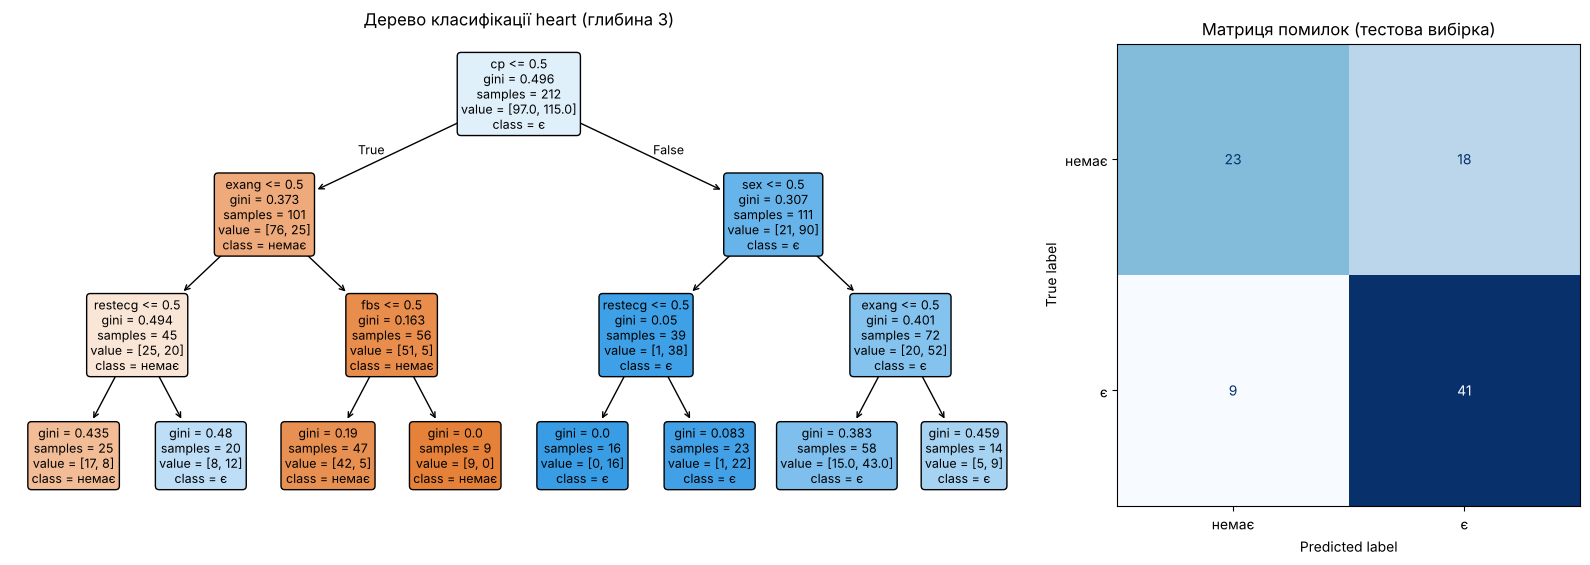

In [ ]:
if not os.path.exists('heart.csv'):
    from google.colab import files
    files.upload()                      # оберіть файл heart.csv
heart = pd.read_csv('heart.csv')
Xh, yh = heart.drop(columns='target'), heart['target']
print(heart.shape, '| частка target=1:', round(yh.mean(), 3))

skf = StratifiedKFold(10, shuffle=True, random_state=SEED)
acc_h = {d: cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), Xh, yh, cv=skf).mean() for d in range(1, 6)}
best_d = min(d for d, a in acc_h.items() if a >= max(acc_h.values()) - 0.005)   # найменша глибина в межах 0,5 п.п. від найкращої
print('Точність CV за глибиною:', {d: round(float(a)*100, 2) for d, a in acc_h.items()})

Xtr, Xte, ytr, yte = train_test_split(Xh, yh, test_size=0.3, stratify=yh, random_state=SEED)
heart_tree = DecisionTreeClassifier(max_depth=best_d, random_state=SEED).fit(Xtr, ytr)
ph = heart_tree.predict(Xte)
print(f'Глибина {best_d}: точність на тесті {accuracy_score(yte, ph)*100:.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
plot_tree(heart_tree, feature_names=Xh.columns, class_names=['немає', 'є'], filled=True, rounded=True, fontsize=9, ax=ax[0])
ax[0].set_title(f'Дерево класифікації heart (глибина {best_d})')
ConfusionMatrixDisplay(confusion_matrix(yte, ph), display_labels=['немає', 'є']).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Матриця помилок (тестова вибірка)')
plt.tight_layout(); plt.show()